# CNN Challenge: CIFAR-10

Diseñá una arquitectura CNN, elegí la cantidad de épocas con `EPOCHS` (20 por defecto; lo mantenemos por tema tiempo en la clase) y entrenala. Analisá su resultado y si te convence podes compartirla para comparar con los demas alumnos. Podés probar varias arquitecturas: cada ejecución del entrenamiento genera un `run_id` nuevo. Editá los parámetros de **Tu arquitectura** y, si cambiás la cantidad de bloques, comentá o descomentá las líneas correspondientes de la clase `CNN`. Al enviar, completá tu alias y los datos de conexión que indique el docente.

El ranking usa la accuracy de **validación**. El conjunto de test queda reservado para la evaluación final del docente.

## Importar lo necesario y establecer las configuraciones necesarias

In [ ]:
import random # para fijar la semilla de los generadores de números aleatorios
import time # para medir el tiempo de ejecución
import uuid # para generar un identificador único
from getpass import getpass # para pedir el TOKEN_CLASE docente sin mostrarla en pantalla

import torch # PyTorch
import torchvision # datasets y transformaciones
import matplotlib.pyplot as plt # para graficar
import requests # para enviar el resultado al docente
from tqdm import tqdm # barra de avance

In [2]:
# instalar torchinfo para ver el modelo y sus parámetros
%pip install torchinfo
import torchinfo as torchinfo


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### Configuramos el `device` de acuerdo con el dispositivo disponible




In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device


'cuda'

### Fijamos semillas para reproducibilidad

Esto se usa para que, al repetir un experimento, los resultados sean más comparables entre corridas.
No garantiza reproducibilidad perfecta en todos los entornos, pero ayuda a reducir variaciones por aleatoriedad.

In [4]:
# Semilla inicial de la sesión: fija el punto de partida de los generadores aleatorios.
# Su estado avanza con cada uso; por eso se reinician también al crear y entrenar un modelo.
# Esto no garantiza resultados idénticos entre equipos o versiones de PyTorch.
SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

SEED


42

## Condiciones comunes del desafío

CIFAR-10, la partición train/eval, las transformaciones, Adam, `lr=1e-3`, batch 64 son fijos. La cantidad de épocas se configura con `EPOCHS`, un entero positivo (20 por defecto). Modificá la arquitectura en la sección **Tu arquitectura**. Para comparar arquitecturas en igualdad de condiciones, usá el mismo presupuesto de épocas. El conjunto de test queda reservado para una evaluación final del docente.

In [ ]:
PROTOCOLO = "CIFAR10_CNN_v1"
EPOCHS = 2  # Podés usar menos, por ejemplo 3 para pruebas.
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
MAX_PARAMETROS = 1_000_000  # Un millón de parámetros.
SESION_ID = uuid.uuid4().hex

if device != "cuda":
    print("Se recomienda activar GPU en Entorno de ejecución > Cambiar tipo de entorno de ejecución.")

## 1. Cargar base de datos

De la documentación, ver:


Transformación `torchvision.transforms.ToTensor()`

```
... Converts a PIL Image or numpy.ndarray (H x W x C) in the range [0, 255] to a torch.FloatTensor of shape (C x H x W) in the range [0.0, 1.0]...
```

Transformación `Normalize`

```
... Normalize a tensor image with mean and standard deviation. ...
```

In [ ]:
# ETIQUETAS
# Nombres en español, en el orden de los índices originales de CIFAR-10 (0 a 9).
# Las etiquetas numéricas del entrenamiento se mantienen sin cambios.
clases = (
    'avión', 'automóvil', 'pájaro', 'gato', 'ciervo',
    'perro', 'rana', 'caballo', 'barco', 'camión',
)


# Media y desvío estándar de los canales RGB de CIFAR-10, para normalizar las imágenes.
media = (0.4914, 0.4822, 0.4465)
desvio = (0.2470, 0.2435, 0.2616)

# Se definen transformaciones diferentes para train y eval, porque se aplican aumentos de datos solo en train.
transformaciones_train = torchvision.transforms.Compose([
    torchvision.transforms.RandomCrop(32, padding=4), # aumenta el tamaño de la imagen a 40x40 (completa con ceros)
                                                    # y luego recorta un área random de 32x32
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(media, desvio),
])

transformaciones_eval = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(media, desvio),
])

# Se descargan los datos de train y eval, aplicando las transformaciones correspondientes.
# Aca los dataset estan duplicados
datos_train = torchvision.datasets.CIFAR10('../data', train=True, download=True,
                                            transform=transformaciones_train)
datos_eval = torchvision.datasets.CIFAR10('../data', train=True, download=False,
                                           transform=transformaciones_eval)


# Definimos un grupo de indices para hacer el entrenamiento y otro para la evaluación.
# Un generador independiente mantiene la partición aunque antes se hayan usado números aleatorios.
indices = torch.randperm(len(datos_train), generator=torch.Generator().manual_seed(SEED)).tolist()
# Con el metodo Subset se crean datasets que contienen solo los indices elegidos.
train_dataset = torch.utils.data.Subset(datos_train, indices[:45_000])
eval_dataset = torch.utils.data.Subset(datos_eval, indices[45_000:])

# pin_memory puede acelerar la transferencia CPU -> GPU si se usa CUDA.
pin_memory = torch.cuda.is_available()

# Se crean los dataloaders para train y eval, con el tamaño de batch definido.
# train se baraja (shuffle) para que cada batch sea diferente en cada época, eval no.
dataloader = {
    'train': torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE,
                shuffle=True, generator=torch.Generator().manual_seed(SEED),
                num_workers=0, pin_memory=pin_memory),
    'eval': torch.utils.data.DataLoader(eval_dataset, batch_size=BATCH_SIZE,
                shuffle=False, num_workers=0, pin_memory=pin_memory),
}
print('Train:', len(train_dataset), '| Eval:', len(eval_dataset))

100%|██████████| 170498071/170498071 [24:38<00:00, 115288.54it/s] 


Extracting ../data\cifar-10-python.tar.gz to ../data
Train: 45000 | Eval: 5000


## 2. Ver que la base de datos esté OK

In [8]:
print(type(dataloader))
print(type(dataloader['train']))


<class 'dict'>
<class 'torch.utils.data.dataloader.DataLoader'>


In [9]:
# Ver imagen y etiqueta del dataloader 
train_features, train_labels = next(iter(dataloader['train']))


In [10]:
# verifico sus dimensiones
print(f"Tamaño del batch de feature (input / imagen): {train_features.size()}")
print(f"Tamaño del batch del label (clase / etiqueta): {train_labels.size()}")


Tamaño del batch de feature (input / imagen): torch.Size([64, 3, 32, 32])
Tamaño del batch del label (clase / etiqueta): torch.Size([64])


Tamaño de una imagen: torch.Size([3, 32, 32])


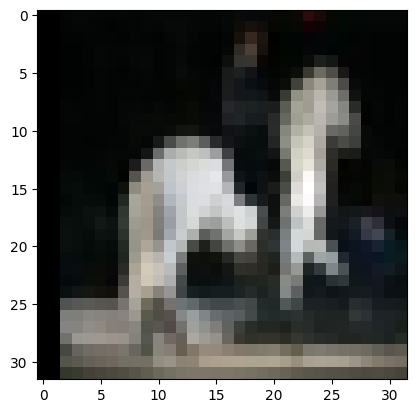

Label: 7


In [11]:
# Visualizo una imagen del batch, deshaciendo la normalización.
img = train_features[5]
label = train_labels[5]
print('Tamaño de una imagen:', img.shape)
img_visible = img * torch.tensor(desvio)[:, None, None] + torch.tensor(media)[:, None, None]
plt.imshow(img_visible.permute(1, 2, 0).clamp(0, 1))
plt.show()
print('Clase:', clases[label.item()], '| Índice:', label.item())

## 3. Construyo mi CNN

#### Bloque de convolución

Usamos el `conv_block(c_in, c_out, k, p, s, pk)` del notebook de clase. Agregamos dos opciones: `usar_batchnorm` y `pooling`. BatchNorm va después de la convolución y antes de ReLU.

In [ ]:
# Bloque de convolución para emplear en mi red.
def conv_block(c_in, c_out, k=3, p='same', s=1, pk=2, usar_batchnorm=False, pooling='max'):
    # Si deseo usar pooling, defino la capa de pooling según el parámetro pooling. Puede ser max pooling o average pooling.    
    capa_pool = torch.nn.MaxPool2d(pk) if pooling == 'max' else torch.nn.AvgPool2d(pk)

    # Armo el sequencial de capas según si quiero usar batchnorm o no. La capa de pooling se agrega al final.
    if usar_batchnorm:
        block =  torch.nn.Sequential(
            torch.nn.Conv2d(c_in, c_out, k, padding=p, stride=s),
            torch.nn.BatchNorm2d(c_out),
            torch.nn.ReLU(),
            capa_pool,
        )
    else:
        block = torch.nn.Sequential(
            torch.nn.Conv2d(c_in, c_out, k, padding=p, stride=s),
            torch.nn.ReLU(),
            capa_pool,
        )
    # devuelvo el bloque de capas
    return block

### Red convolucional (modelo)

Construimos la red con `conv_block`, dropout y `fc`. Para usar menos o más bloques (máximo 4), el alumno comentar/descomentar los bloques necesarios **en `__init__` y en `forward`**. 

**La entrada de `fc` se calcula a mano.** Con imágenes CIFAR-10 de 32 × 32, `padding='same'`, `stride=1` y pooling de 2 × 2, cada `conv_block` divide por dos el lado: 32 → 16 → 8 → 4 → 2. 

Ejemplo: Con tres bloques y 128 canales finales, `fc` recibe `128 × 4 × 4` valores. Si cambiás la cantidad de bloques, cambiá también `final_size` en **Tu arquitectura**.

In [ ]:
class CNN(torch.nn.Module):
  def __init__(self, n_channels=3, n_outputs=10, channels=(32, 64, 128), kernel_size=3,
               dropout=0.25, padding='same', stride=1, pool_kernel=2,
               usar_batchnorm=True, pooling='max', final_size=4):
    super().__init__()
    # Guardo hiperparámetros del modelo para registrarlos automáticamente.
    self.n_channels = n_channels
    self.n_outputs = n_outputs
    self.channels = tuple(channels)
    self.kernel_size = kernel_size
    self.dropout_p = dropout
    self.padding = padding
    self.stride = stride
    self.pool_kernel = pool_kernel
    self.usar_batchnorm = usar_batchnorm
    self.pooling = pooling
    self.final_size = final_size
    self.num_conv_blocks = len(self.channels)

    # Defino mis capas de convolución y la capa lineal final. Guardo las salidas de cada bloque para poder visualizarlas.
    self.conv1 = conv_block(c_in=self.n_channels, c_out=self.channels[0],
        k=self.kernel_size, p=self.padding, s=self.stride, pk=self.pool_kernel,
        usar_batchnorm=self.usar_batchnorm, pooling=self.pooling)
    self.conv1_out = None
    
    self.conv2 = conv_block(c_in=self.channels[0], c_out=self.channels[1],
        k=self.kernel_size, p=self.padding, s=self.stride, pk=self.pool_kernel,
        usar_batchnorm=self.usar_batchnorm, pooling=self.pooling)
    self.conv2_out = None
    
    self.conv3 = conv_block(c_in=self.channels[1], c_out=self.channels[2],
        k=self.kernel_size, p=self.padding, s=self.stride, pk=self.pool_kernel,
        usar_batchnorm=self.usar_batchnorm, pooling=self.pooling)
    self.conv3_out = None
    
    # Para cuatro bloques, descomentá también conv4 en forward.
    # self.conv4 = conv_block(c_in=self.channels[2], c_out=self.channels[3],
    #     k=self.kernel_size, p=self.padding, s=self.stride, pk=self.pool_kernel,
    #     usar_batchnorm=self.usar_batchnorm, pooling=self.pooling)
    # self.conv4_out = None

    # Dropout.
    self.drop = torch.nn.Dropout2d(p=self.dropout_p, inplace=False)
    
    # Capa lineal final, que recibe la salida del último bloque de convolución aplanada.
    # Es necesario calcular el final_size que se pone como argumento a la clase.
    self.fc = torch.nn.Linear(self.channels[-1] * self.final_size * self.final_size,
                              self.n_outputs)

  def forward(self, x):
    self.conv1_out = self.conv1(x)
    y = self.conv1_out
    self.conv2_out = self.conv2(y)
    y = self.conv2_out
    self.conv3_out = self.conv3(y)
    y = self.conv3_out
    # Para cuatro bloques, descomentá estas dos líneas.
    # self.conv4_out = self.conv4(y)
    # y = self.conv4_out
    y = self.drop(y)
    y = y.flatten(start_dim=1)
    y = self.fc(y)
    return y

#### Tu arquitectura: editá estos valores y, si cambiás bloques, la clase CNN

Elige la arquitectura (numero de bloques de `conv_block`) que consideres. Ajustá `channels` al número de bloques activos (entre uno y cuatro). Calculá **a mano** el lado del mapa que llega a `fc` y escribilo en `final_size`: con un `conv_block` vale 16; con dos `conv_block`, 8; con tres `conv_block`, 4; con cuatro `conv_block`, 2. Se propone un límite de un millón de parámetros entrenables.

Para que el envío sea aceptado: cada canal debe ser un entero positivo (se permiten 1, 2, 3, etc.); `kernel_size` puede ser cualquier entero positivo, par o impar, sin límite superior; `dropout` debe estar entre 0 y 0.6; y `pooling` puede ser `'max'` o `'avg'`.

Para un nuevo intento, si editaste la clase `CNN`, reejecutá también su celda. Después reejecutá esta celda, la creación de `model`, la celda del optimizer y el entrenamiento. Revisá las curvas antes de decidir si enviás el resultado.

In [25]:
channels = (1, 2, 3)
kernel_size = 3
usar_batchnorm = True
dropout = 0.25
pooling = 'max'
final_size = 4  # calculado para 3 bloques: 32 -> 16 -> 8 -> 4

In [ ]:
# Reinicio las semillas para repetir la inicialización de pesos de una misma arquitectura
# al reejecutar esta celda, sin depender de las operaciones aleatorias anteriores.
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Instancio modelo.
model = CNN(n_channels=3, n_outputs=10, channels=channels, kernel_size=kernel_size,
            dropout=dropout, usar_batchnorm=usar_batchnorm, pooling=pooling,
            final_size=final_size)

# Verifico la cantidad de parámetros a entrenar y comparo con el límite propuesto.
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('Red creada:')
print(model)
print('Número total de parámetros a entrenar:', trainable_params)
print('Límite propuesto:', MAX_PARAMETROS)
if trainable_params > MAX_PARAMETROS:
    print('Atención: esta arquitectura supera el límite y no se podrá enviar.')

# Armo la configuración a partir del modelo ya construido.
model_config = {
    'architecture': model.__class__.__name__,
    'input_channels': model.n_channels,
    'output_classes': model.n_outputs,
    'num_conv_blocks': model.num_conv_blocks,
    'filtros': list(model.channels),  # nombre esperado por el tablero docente
    'kernel_size': model.kernel_size,
    'dropout': model.dropout_p,
    'padding': model.padding,
    'stride': model.stride,
    'pool_kernel': model.pool_kernel,
    'usar_batchnorm': model.usar_batchnorm,
    'pooling': model.pooling,
    'final_size': model.final_size,
    'trainable_params': trainable_params,
}

Red creada:
CNN(
  (conv1): Sequential(
    (0): Conv2d(3, 1, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): BatchNorm2d(1, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(1, 2, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): BatchNorm2d(2, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(2, 3, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (drop): Dropout2d(p=0.25, inplace=False)
  (fc): Linear(in_features=48, out_features=10, bias=True)
)
Número total de parám

In [27]:
model_config


{'architecture': 'CNN',
 'input_channels': 3,
 'output_classes': 10,
 'num_conv_blocks': 3,
 'channels': [1, 2, 3],
 'filtros': [1, 2, 3],
 'kernel_size': 3,
 'dropout': 0.25,
 'padding': 'same',
 'stride': 1,
 'pool_kernel': 2,
 'usar_batchnorm': True,
 'pooling': 'max',
 'final_size': 4,
 'trainable_params': 607}

## 4. Veamos que las dimensiones sean consistentes.

In [28]:
# Igual que en clase, comprobamos tamaños y parámetros intermedios.
torchinfo.summary(model, input_size=(12, model.n_channels, 32, 32))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [12, 10]                  --
├─Sequential: 1-1                        [12, 1, 16, 16]           --
│    └─Conv2d: 2-1                       [12, 1, 32, 32]           28
│    └─BatchNorm2d: 2-2                  [12, 1, 32, 32]           2
│    └─ReLU: 2-3                         [12, 1, 32, 32]           --
│    └─MaxPool2d: 2-4                    [12, 1, 16, 16]           --
├─Sequential: 1-2                        [12, 2, 8, 8]             --
│    └─Conv2d: 2-5                       [12, 2, 16, 16]           20
│    └─BatchNorm2d: 2-6                  [12, 2, 16, 16]           4
│    └─ReLU: 2-7                         [12, 2, 16, 16]           --
│    └─MaxPool2d: 2-8                    [12, 2, 8, 8]             --
├─Sequential: 1-3                        [12, 3, 4, 4]             --
│    └─Conv2d: 2-9                       [12, 3, 8, 8]             57
│    └─BatchNorm2

## 5. Armo las funciones necesarias

In [29]:
# Definimos el optimizer y la función de pérdida; son fijos para todos.
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
model_config['optimizer'] = optimizer.__class__.__name__
loss_fn = torch.nn.CrossEntropyLoss()

# No usamos scheduler ni early stopping: se completan las épocas configuradas.

In [30]:
# Mismos argumentos y fases train/eval que train_model del notebook de clase.
def train_model(model, optimizer, train_loader, eval_loader, loss_module, num_epochs=EPOCHS):
    if type(num_epochs) is not int or num_epochs < 1:
        raise ValueError("La cantidad de épocas debe ser un entero positivo.")
    model.to(device)
    # Reinicio los generadores al comenzar cada entrenamiento, no en cada época.
    # Así augmentation y dropout parten de estados conocidos; arquitecturas distintas
    # pueden consumir números aleatorios de manera diferente. Esto no reinicia los pesos.
    random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    # Reinicio también el orden de los lotes, incluso si antes visualicé un batch.
    train_loader.generator.manual_seed(SEED)

    history = {
        'train_loss': [], 'train_accuracy': [],
        'eval_loss': [], 'eval_accuracy': [], 'learning_rate': [],
    }
    for epoch in tqdm(range(num_epochs), desc='Progreso de Epoch'):
        ### Fase de entrenamiento ###
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_samples = 0
        for X, y in train_loader:
            data_inputs = X.to(device)
            data_labels = y.to(device)
            preds = model(data_inputs)
            loss = loss_module(preds, data_labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * data_labels.size(0)
            train_correct += (preds.argmax(dim=1) == data_labels).sum().item()
            train_samples += data_labels.size(0)
        train_loss /= train_samples
        train_accuracy = train_correct / train_samples

        ### Fase de evaluación ###
        model.eval()
        eval_loss = 0.0
        eval_correct = 0
        eval_samples = 0
        with torch.no_grad():
            for X, y in eval_loader:
                data_inputs = X.to(device)
                data_labels = y.to(device)
                preds = model(data_inputs)
                loss = loss_module(preds, data_labels)
                eval_loss += loss.item() * data_labels.size(0)
                eval_correct += (preds.argmax(dim=1) == data_labels).sum().item()
                eval_samples += data_labels.size(0)
        eval_loss /= eval_samples
        eval_accuracy = eval_correct / eval_samples

        history['train_loss'].append(train_loss)
        history['train_accuracy'].append(train_accuracy)
        history['eval_loss'].append(eval_loss)
        history['eval_accuracy'].append(eval_accuracy)
        history['learning_rate'].append(optimizer.param_groups[0]['lr'])
        print(f'Epoch {epoch+1}/{num_epochs} - Train Loss: {train_loss:.4f} - Train Acc: {train_accuracy:.4f} '
              f'| Eval Loss: {eval_loss:.4f} - Eval Acc: {eval_accuracy:.4f}')
    return history

## 6. Entrenamiento local


Progreso de Epoch:   5%|▌         | 1/20 [00:19<06:05, 19.26s/it]

Epoch 1/20 - Train Loss: 2.2191 - Train Acc: 0.1778 | Eval Loss: 1.9984 - Eval Acc: 0.2814


Progreso de Epoch:  10%|█         | 2/20 [00:37<05:38, 18.81s/it]

Epoch 2/20 - Train Loss: 2.0051 - Train Acc: 0.2656 | Eval Loss: 1.8890 - Eval Acc: 0.3160


Progreso de Epoch:  15%|█▌        | 3/20 [00:56<05:18, 18.73s/it]

Epoch 3/20 - Train Loss: 1.9606 - Train Acc: 0.2805 | Eval Loss: 1.8514 - Eval Acc: 0.3292


... (30 outputs left out)

Progreso de Epoch:  95%|█████████▌| 19/20 [05:50<00:18, 18.29s/it]

Epoch 19/20 - Train Loss: 1.8727 - Train Acc: 0.3101 | Eval Loss: 1.7647 - Eval Acc: 0.3582


Progreso de Epoch: 100%|██████████| 20/20 [06:08<00:00, 18.43s/it]

Epoch 20/20 - Train Loss: 1.8666 - Train Acc: 0.3114 | Eval Loss: 1.7508 - Eval Acc: 0.3626


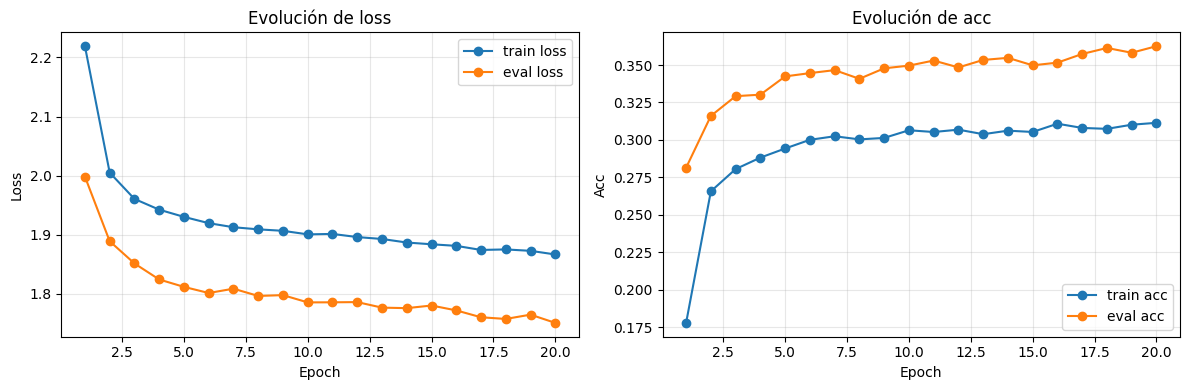

In [80]:
# Entrenamos con los mismos argumentos que en clase, usando eval en lugar de test.
inicio = time.perf_counter()
history = train_model(model, optimizer, dataloader['train'], dataloader['eval'], loss_fn,
                      num_epochs=EPOCHS)
training_time = round(time.perf_counter() - inicio, 2)
run_id = str(uuid.uuid4())

# Graficamos la evolución de train/eval loss y train/eval acc.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, len(history['train_loss']) + 1)
axes[0].plot(epochs, history['train_loss'], marker='o', label='train loss')
axes[0].plot(epochs, history['eval_loss'], marker='o', label='eval loss')
axes[0].set_title('Evolución de loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].plot(epochs, history['train_accuracy'], marker='o', label='train acc')
axes[1].plot(epochs, history['eval_accuracy'], marker='o', label='eval acc')
axes[1].set_title('Evolución de acc')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Acc')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Vemos que funcione

Probamos una imagen de **eval**, no de test. La red devuelve diez logits y `softmax` los convierte en probabilidades para mostrarlas.

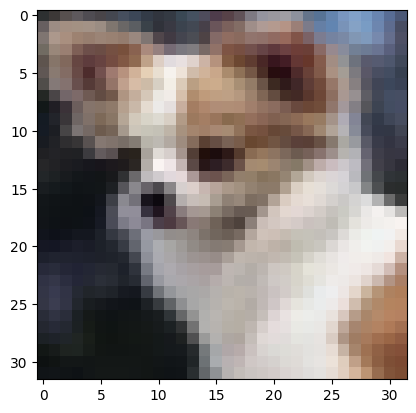

Clase real: 5
Predicción del modelo: 7
Softmax de la predicción: tensor([[0.0378, 0.0446, 0.1368, 0.1341, 0.0954, 0.1709, 0.0535, 0.2338, 0.0178,
         0.0753]], device='cuda:0')


In [32]:
eval_features, eval_labels = next(iter(dataloader['eval']))
k = random.randint(0, eval_features.size(0) - 1)
selected_img = eval_features[k]
img_visible = selected_img * torch.tensor(desvio)[:, None, None] + torch.tensor(media)[:, None, None]
plt.imshow(img_visible.permute(1, 2, 0).clamp(0, 1))
plt.show()
model_input = selected_img.unsqueeze(0).to(device)
model.eval()
with torch.no_grad():
    y_hat = model(model_input)
indice_real = eval_labels[k].item()
indice_predicho = torch.argmax(y_hat, dim=1).item()
print('Clase real:', clases[indice_real], '| Índice:', indice_real)
print('Predicción del modelo:', clases[indice_predicho], '| Índice:', indice_predicho)
print('Softmax de la predicción:', torch.nn.functional.softmax(y_hat, dim=1))

## 8. Envío de resultados (opcional)

Primero entrená y revisá las curvas. **Solo si estás conforme**, completá `ALUMNO` y `COHORTE`, y ejecutá la celda siguiente. No se envía nada durante el entrenamiento. El token se solicita al ejecutar la celda y no se guarda en el notebook.

Si falla la conexión, podés volver a ejecutar la misma celda: el `run_id` generado al terminar el entrenamiento evita duplicar el intento. Para probar otra arquitectura, regresá a **Tu arquitectura** y repetí el entrenamiento.

In [ ]:
# Completar estos dos valores y ejecuta la celda únicamente si se decide enviar la corrida.
ALUMNO = 'Cr'
COHORTE = 'test'

def enviar_resultados(resultado, alumno, cohorte, endpoint, token):
    payload = {**resultado, 'alumno': alumno.strip(), 'cohorte': cohorte.strip(), 'token': token}
    try:
        respuesta = requests.post(endpoint, json=payload, timeout=30)
        respuesta.raise_for_status()
        datos = respuesta.json()
    except (requests.RequestException, ValueError) as error:
        print('No se pudo enviar el resultado:', error)
        return None
    if datos.get('ok'):
        print('Registro recibido:', datos['run_id'])
    else:
        print('El servidor rechazó el resultado:', datos.get('error', 'Error desconocido'))
    return datos


ENDPOINT = 'https://script.google.com/macros/s/AKfycbzcj5rreCM71dcN3MFyFB191Mk36ugSFyYId93DhNqat2N7ItSSdn2QvZ6k2UQiLwaqIQ/exec'

if not ALUMNO or not COHORTE or not ENDPOINT:
    print('Para enviar, completá ALUMNO, COHORTE y ENDPOINT en esta celda.')
elif not history['eval_accuracy'] or any(
    len(history[k]) != len(history['eval_accuracy'])
    for k in ('train_loss', 'eval_loss', 'train_accuracy')
):
    print('Los historiales deben tener la misma cantidad positiva de épocas.')
elif trainable_params > MAX_PARAMETROS:
    print('La arquitectura supera el límite de parámetros.')
else:
    resultado = {
        'run_id': run_id, 'sesion_id': SESION_ID, 'protocolo': PROTOCOLO,
        'arquitectura': dict(model_config), 'n_parametros': trainable_params,
        'epochs': len(history['eval_accuracy']),  # Épocas realmente entrenadas.
        'train_loss': list(history['train_loss']), 'val_loss': list(history['eval_loss']),
        'train_acc': list(history['train_accuracy']), 'val_acc': list(history['eval_accuracy']),
        'best_val_acc': max(history['eval_accuracy']),
        'final_val_acc': history['eval_accuracy'][-1], 'training_time': training_time,
    }
    print('Run ID:', run_id, '| Mejor eval acc:', f"{resultado['best_val_acc']:.3f}")
    token_clase = getpass('Token de la clase: ')
    confirmacion = enviar_resultados(resultado, ALUMNO, COHORTE, ENDPOINT, token_clase)
    del token_clase

Run ID: c68efc46-73c5-4620-9a70-b6afacaed563 | Mejor eval acc: 0.363
El servidor rechazó el resultado: Arquitectura inválida
